# EN3150 Assignment 03 — Part 5: Fine-tuning MobileNetV2

## 1. Setup

MobileNetV2 uses ImageNet normalization to match its pretrained weights. The same images and train/validation/test split are used as in Models A and B. Torchvision downloads the pretrained weights automatically on first use (internet required).

In [1]:
from a03_common import *
from torchvision import models

FREEZE_EPOCHS = 3        # phase 1: train the new head only
FINETUNE_EPOCHS = 12     # phase 2: fine-tune the whole network
HEAD_LR, BACKBONE_LR = 1e-3, 2e-4

set_seed(SEED)
print("Device:", DEVICE)
data = Data(norm="imagenet", batch_size=64, augment=True)
print("Train/Val/Test:", len(data.idx["train"]), len(data.idx["val"]), len(data.idx["test"]))

Device: cpu
Train/Val/Test: 18900 4050 4050


## 2. Model: MobileNetV2
- Uses inverted residual blocks and depthwise-separable convolutions, similar to Model B.
- Designed for efficient mobile and edge-device applications, with approximately 3.5 million parameters.
- Replaces the original 1000-class classifier with a new 10-class output layer for EuroSAT.

In [2]:
weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
model = models.mobilenet_v2(weights=weights)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, data.num_classes)   # new 10-class head
model = model.to(DEVICE)

total, trainable = count_params(model)
print(f"MobileNetV2 | total params: {total:,} | trainable: {trainable:,}")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\Asus/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100.0%


MobileNetV2 | total params: 2,236,682 | trainable: 2,236,682
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)


## 3. Fine-tuning strategy (two phases)
Training Strategy
- Phase 1 (3 epochs): Train only the classifier using Adam (learning rate = 0.001).
- Phase 2 (12 epochs): Fine-tune the entire network using a lower backbone learning rate (0.0002) and a higher classifier learning rate (0.001).
Notes
- Images are \(64\times64\), reducing computation compared with \(224\times224\) inputs but potentially lowering accuracy.
- BatchNorm statistics adapt to satellite images during training.
- Total training time is limited by using 15 epochs, suitable for CPU training.

In [3]:
HEAD = "classifier"

def set_trainable(model, backbone):
    for n, p in model.named_parameters():
        p.requires_grad = n.startswith(HEAD) or backbone

total, _ = count_params(model)

# ---- phase 1: head only ----
set_trainable(model, backbone=False)
_, trainable = count_params(model)
print(f"Phase 1: total params {total:,} | trainable {trainable:,}")
opt1 = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=HEAD_LR)
hist = train_model(model, opt1, data, FREEZE_EPOCHS, name="MobileNetV2 phase 1")

# ---- phase 2: whole network ----
set_trainable(model, backbone=True)
_, trainable = count_params(model)
print(f"\nPhase 2: total params {total:,} | trainable {trainable:,}")
backbone = [p for n, p in model.named_parameters() if not n.startswith(HEAD)]
head = [p for n, p in model.named_parameters() if n.startswith(HEAD)]
opt2 = torch.optim.Adam([{"params": backbone, "lr": BACKBONE_LR}, {"params": head, "lr": HEAD_LR}])
hist = train_model(model, opt2, data, FINETUNE_EPOCHS, name="MobileNetV2 phase 2", hist=hist)

Phase 1: total params 2,236,682 | trainable 12,810
[MobileNetV2 phase 1] epoch 01 | train loss 0.7088 acc 0.7902 | val loss 0.4572 acc 0.8622 | 32.7s
[MobileNetV2 phase 1] epoch 02 | train loss 0.4669 acc 0.8513 | val loss 0.3934 acc 0.8741 | 31.2s
[MobileNetV2 phase 1] epoch 03 | train loss 0.4395 acc 0.8572 | val loss 0.3779 acc 0.8765 | 34.0s
[MobileNetV2 phase 1] best validation accuracy 0.8765 | mean time/epoch (this call) 32.6s

Phase 2: total params 2,236,682 | trainable 2,236,682
[MobileNetV2 phase 2] epoch 04 | train loss 0.2532 acc 0.9191 | val loss 0.1361 acc 0.9531 | 212.9s
[MobileNetV2 phase 2] epoch 05 | train loss 0.1392 acc 0.9549 | val loss 0.1127 acc 0.9612 | 174.9s
[MobileNetV2 phase 2] epoch 06 | train loss 0.1192 acc 0.9619 | val loss 0.0988 acc 0.9674 | 181.2s
[MobileNetV2 phase 2] epoch 07 | train loss 0.0922 acc 0.9708 | val loss 0.0829 acc 0.9731 | 181.2s
[MobileNetV2 phase 2] epoch 08 | train loss 0.0849 acc 0.9720 | val loss 0.0732 acc 0.9728 | 185.3s
[Mobile

## 4. Learning curves
The dashed line marks the end of phase 1. A visible drop in validation loss right after it is the benefit of unfreezing the backbone.

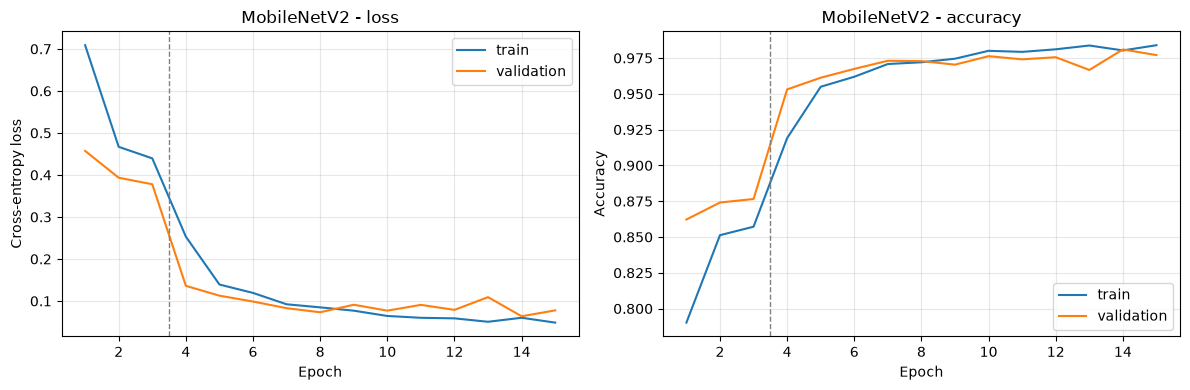

In [4]:
plot_history(hist, "MobileNetV2", "mobilenetv2_curves.png", marks=[FREEZE_EPOCHS])

## 5. Test-set evaluation

Test accuracy: 0.9768
Macro precision: 0.9761 | Macro recall: 0.9759 | Macro F1: 0.9759

                      precision    recall  f1-score   support

          AnnualCrop     0.9625    0.9689    0.9657       450
              Forest     0.9911    0.9867    0.9889       450
HerbaceousVegetation     0.9821    0.9733    0.9777       450
             Highway     0.9861    0.9467    0.9660       375
          Industrial     0.9786    0.9760    0.9773       375
             Pasture     0.9572    0.9700    0.9636       300
       PermanentCrop     0.9703    0.9573    0.9638       375
         Residential     0.9782    0.9956    0.9868       450
               River     0.9635    0.9867    0.9750       375
             SeaLake     0.9912    0.9978    0.9945       450

            accuracy                         0.9768      4050
           macro avg     0.9761    0.9759    0.9759      4050
        weighted avg     0.9769    0.9768    0.9768      4050



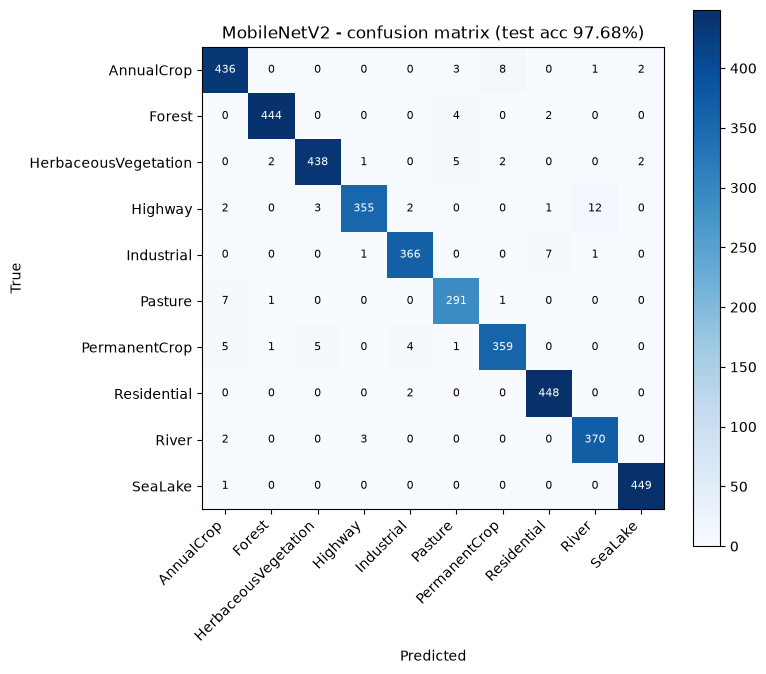

Most confused pairs (true -> predicted : count)
  Highway -> River : 12
  AnnualCrop -> PermanentCrop : 8
  Pasture -> AnnualCrop : 7
  Industrial -> Residential : 7
  PermanentCrop -> HerbaceousVegetation : 5


In [5]:
ev = evaluate(model, data)
cm = plot_confusion(ev["y_true"], ev["y_pred"], data.classes,
                    f"MobileNetV2 - confusion matrix (test acc {ev['acc']:.2%})", "mobilenetv2_confusion.png")

## 6. Parameter count, model size (MB) and cost metrics
Model size is measured from the float32 state_dict. Time per epoch refers to Phase 2 fine-tuning, and all results are saved to JSON for the final model comparison.

In [6]:
total, trainable = count_params(model)
ft_time = float(np.mean(hist["epoch_time"][FREEZE_EPOCHS:]))
res = save_results("mobilenetv2", "MobileNetV2 (fine-tuned)", model, hist, ev,
                   "Adam, 2-phase fine-tuning", data, time_per_epoch_s=ft_time,
                   extra={"time_per_epoch_phase1_s": float(np.mean(hist["epoch_time"][:FREEZE_EPOCHS]))})
print(f"\nTotal parameters: {total:,} | Model size: {res['size_kb']/1024:.2f} MB")

{
  "model": "MobileNetV2 (fine-tuned)",
  "optimizer": "Adam, 2-phase fine-tuning",
  "epochs": 15,
  "params": 2236682,
  "trainable_params": 2236682,
  "macs": 24461312,
  "size_kb": 8972.9,
  "time_per_epoch_s": 184.42,
  "latency_ms_cpu": 15.02,
  "best_val_acc": 0.9809876543209877,
  "test_acc": 0.9767901234567902,
  "macro_precision": 0.9760712047632836,
  "macro_recall": 0.9758888888888888,
  "macro_f1": 0.9759050820746722,
  "time_per_epoch_phase1_s": 32.636426289876304
}

Total parameters: 2,236,682 | Model size: 8.76 MB
